In [12]:
query = """
SELECT
    Exited,
    COUNT(*) AS total_customers,
    ROUND(AVG(Balance), 2) AS average_balance
FROM customers
GROUP BY Exited;
"""

pd.read_sql_query(query, conn)

,Exited,total_customers,average_balance
0,0,7963,72745.30
1,1,2037,91108.54


In [11]:
query = """
SELECT
    NumOfProducts,
    COUNT(*) AS total_customers,
    SUM(Exited) AS churned_customers,
    ROUND(100.0 * SUM(Exited) / COUNT(*), 2) AS churn_rate
FROM customers
GROUP BY NumOfProducts
ORDER BY NumOfProducts;
"""

pd.read_sql_query(query, conn)

,NumOfProducts,total_customers,churned_customers,churn_rate
0,1,5084,1409,27.71
1,2,4590,348,7.58
2,3,266,220,82.71
3,4,60,60,100.00


In [10]:
query = """
SELECT
    IsActiveMember,
    COUNT(*) AS total_customers,
    SUM(Exited) AS churned_customers,
    ROUND(100.0 * SUM(Exited) / COUNT(*), 2) AS churn_rate
FROM customers
GROUP BY IsActiveMember
ORDER BY churn_rate DESC;
"""

pd.read_sql_query(query, conn)

,IsActiveMember,total_customers,churned_customers,churn_rate
0,0,4849,1302,26.85
1,1,5151,735,14.27


In [9]:
query = """
SELECT
    CASE
        WHEN Age < 26 THEN '18-25'
        WHEN Age < 36 THEN '26-35'
        WHEN Age < 46 THEN '36-45'
        WHEN Age < 56 THEN '46-55'
        ELSE '56+'
    END AS age_group,
    COUNT(*) AS total_customers,
    SUM(Exited) AS churned_customers,
    ROUND(100.0 * SUM(Exited) / COUNT(*), 2) AS churn_rate
FROM customers
GROUP BY age_group
ORDER BY churn_rate DESC;
"""

pd.read_sql_query(query, conn)

,age_group,total_customers,churned_customers,churn_rate
0,46-55,1311,663,50.57
1,56+,800,294,36.75
2,36-45,3736,733,19.62
3,26-35,3542,301,8.50
4,18-25,611,46,7.53


In [8]:
query = """
SELECT
    Geography,
    COUNT(*) AS total_customers,
    SUM(Exited) AS churned_customers,
    ROUND(100.0 * SUM(Exited) / COUNT(*), 2) AS churn_rate
FROM customers
GROUP BY Geography
ORDER BY churn_rate DESC;
"""

pd.read_sql_query(query, conn)

,Geography,total_customers,churned_customers,churn_rate
0,Germany,2509,814,32.44
1,Spain,2477,413,16.67
2,France,5014,810,16.15


In [7]:
query = """
SELECT
    ROUND(100.0 * SUM(Exited) / COUNT(*), 2) AS churn_rate_percentage
FROM customers;
"""

pd.read_sql_query(query, conn)

,churn_rate_percentage
0,20.37


In [6]:
query = """
SELECT COUNT(*) AS churned_customers
FROM customers
WHERE Exited = 1;
"""

pd.read_sql_query(query, conn)

,churned_customers
0,2037


In [5]:
query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

pd.read_sql_query(query, conn)

,total_customers
0,10000


In [4]:
query = "SELECT * FROM customers LIMIT 5;"
pd.read_sql_query(query, conn)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
conn = sqlite3.connect("../data/bank_churn.db")

df.to_sql("customers", conn, if_exists="replace", index=False)

print("Database created successfully!")

Database created successfully!


In [2]:
import pandas as pd
import sqlite3

df = pd.read_csv("../data/Churn_Modelling.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(10000, 14)


In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/bank_churn.db")

df.to_sql("customers", conn, if_exists="replace", index=False)

print("Database created successfully!")

NameError: name 'df' is not defined

Exited             1.000000
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
HasCrCard         -0.007138
Tenure            -0.014001
CreditScore       -0.027094
NumOfProducts     -0.047820
IsActiveMember    -0.156128
Name: Exited, dtype: float64


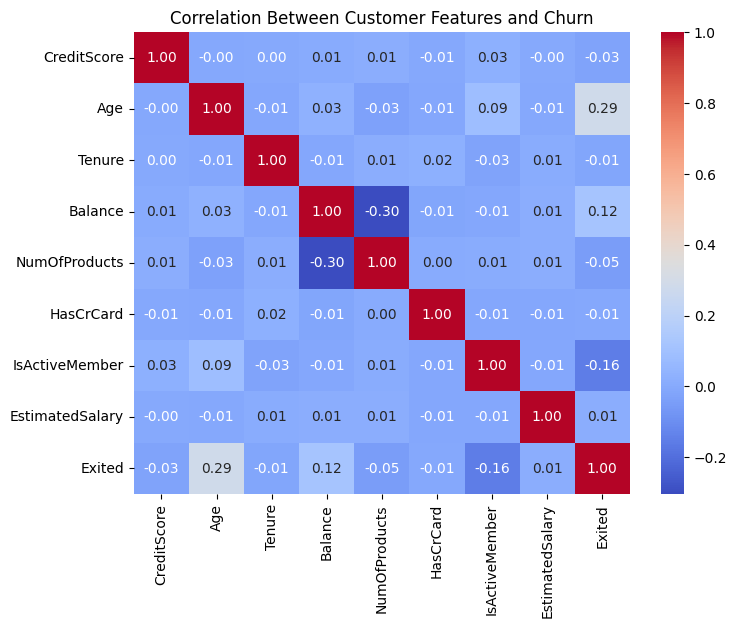

In [35]:
numeric_columns = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary",
    "Exited"
]

correlation = df[numeric_columns].corr()

print(correlation["Exited"].sort_values(ascending=False))
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Customer Features and Churn")

plt.show()

In [34]:
df["RiskCategory"].value_counts()
risk_churn = df.groupby("RiskCategory")["Exited"].mean() * 100

print(risk_churn)

RiskCategory
High Risk      44.615385
Low Risk        7.882577
Medium Risk    17.658880
Name: Exited, dtype: float64


In [33]:
def risk_category(age):
    if age >= 45:
        return "High Risk"
    elif age >= 35:
        return "Medium Risk"
    else:
        return "Low Risk"

df["RiskCategory"] = df["Age"].apply(risk_category)

In [32]:
def risk_category(age):
    if age >= 45:
        return "High Risk"
    elif age >= 35:
        return "Medium Risk"
    else:
        return "Low Risk"

df["RiskCategory"] = df["Age"].apply(risk_category)

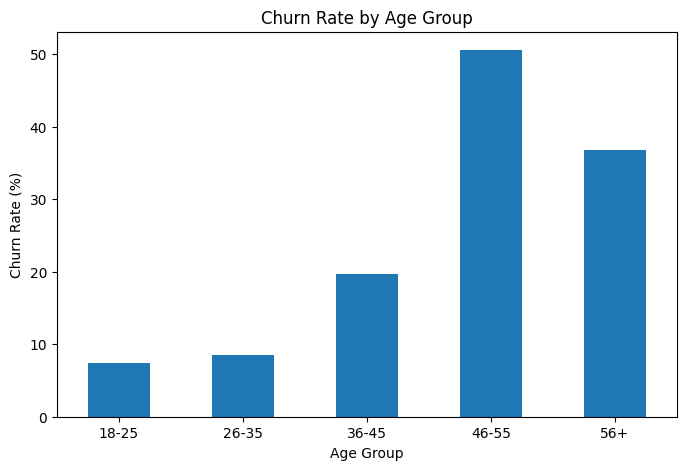

In [31]:
plt.figure(figsize=(8,5))

age_churn.plot(kind="bar")

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [30]:
age_churn = df.groupby("AgeGroup", observed=True)["Exited"].mean() * 100

print(age_churn)

AgeGroup
18-25     7.470289
26-35     8.498024
36-45    19.619914
46-55    50.572082
56+      36.750000
Name: Exited, dtype: float64


In [28]:
df[["Age", "AgeGroup", "Exited"]].head(10)

,Age,AgeGroup,Exited
0,42,36-45,1
1,41,36-45,0
2,42,36-45,1
3,39,36-45,0
4,43,36-45,0
5,44,36-45,1
6,50,46-55,0
7,29,26-35,1
8,44,36-45,0
9,27,26-35,0


In [27]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[18, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

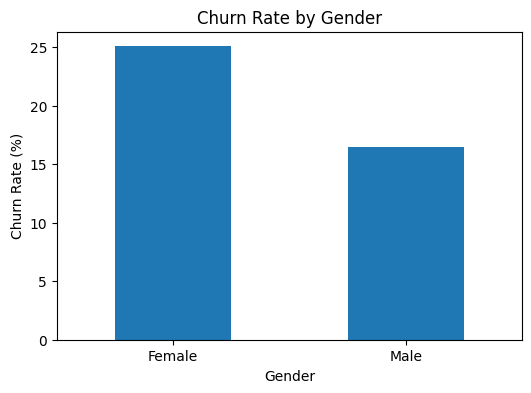

In [26]:
plt.figure(figsize=(6,4))

gender_churn.plot(kind="bar")

plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [25]:
gender_churn = df.groupby("Gender")["Exited"].mean() * 100

print(gender_churn)

Gender
Female    25.071539
Male      16.455928
Name: Exited, dtype: float64


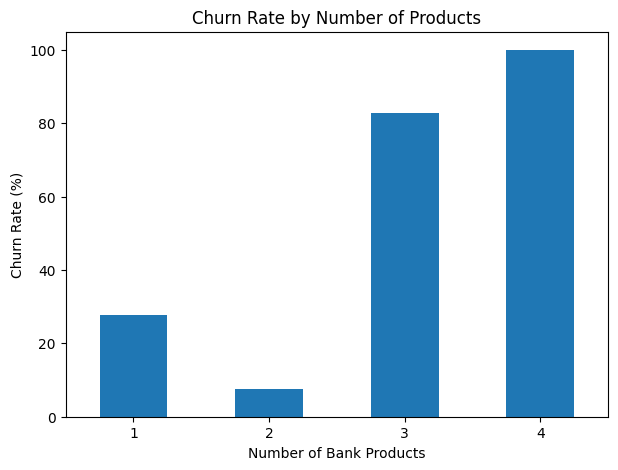

In [24]:
plt.figure(figsize=(7,5))

product_churn.plot(kind="bar")

plt.title("Churn Rate by Number of Products")
plt.xlabel("Number of Bank Products")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [23]:
product_churn = df.groupby("NumOfProducts")["Exited"].mean() * 100

print(product_churn)

NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64


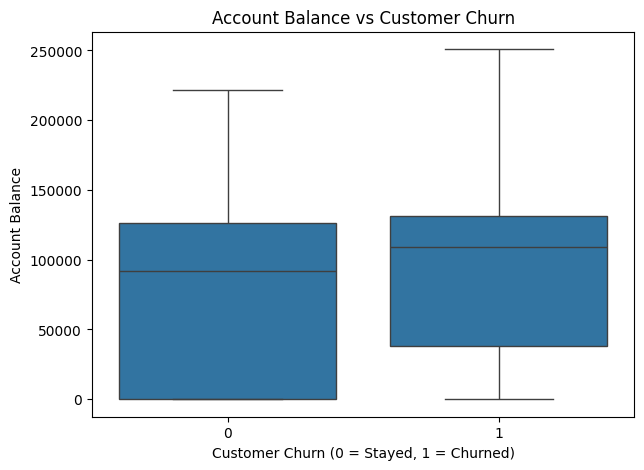

In [22]:
plt.figure(figsize=(7,5))

sns.boxplot(x="Exited", y="Balance", data=df)

plt.title("Account Balance vs Customer Churn")
plt.xlabel("Customer Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Account Balance")

plt.show()

In [21]:
df.groupby("Exited")["Balance"].mean()

Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64

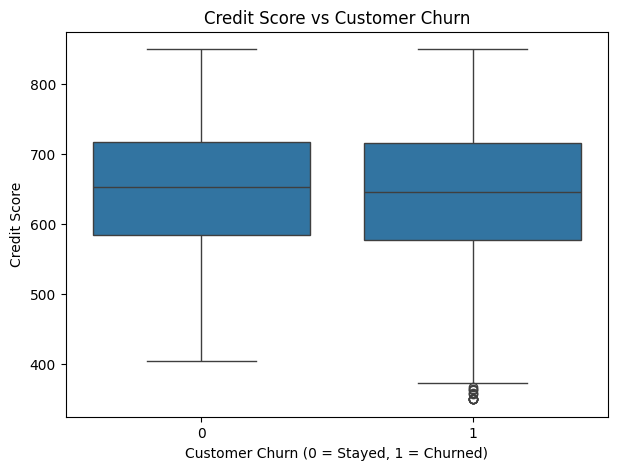

In [20]:
plt.figure(figsize=(7,5))

sns.boxplot(x="Exited", y="CreditScore", data=df)

plt.title("Credit Score vs Customer Churn")
plt.xlabel("Customer Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Credit Score")

plt.show()

In [19]:
df.groupby("Exited")["CreditScore"].mean()

Exited
0    651.853196
1    645.351497
Name: CreditScore, dtype: float64

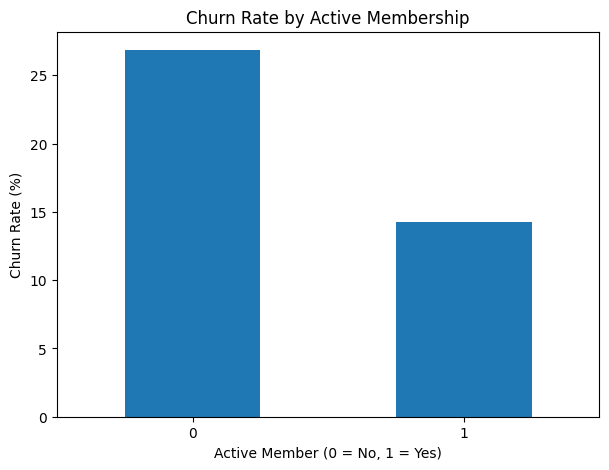

In [18]:
plt.figure(figsize=(7,5))

active_churn.plot(kind="bar")

plt.title("Churn Rate by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [17]:
active_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

print(active_churn)


IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


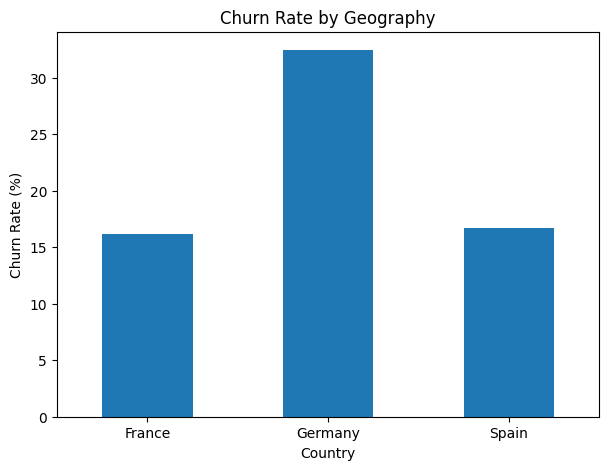

In [16]:
plt.figure(figsize=(7,5))

geo_churn.plot(kind="bar")

plt.title("Churn Rate by Geography")
plt.xlabel("Country")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [15]:
geo_churn = df.groupby("Geography")["Exited"].mean() * 100

print(geo_churn)

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64


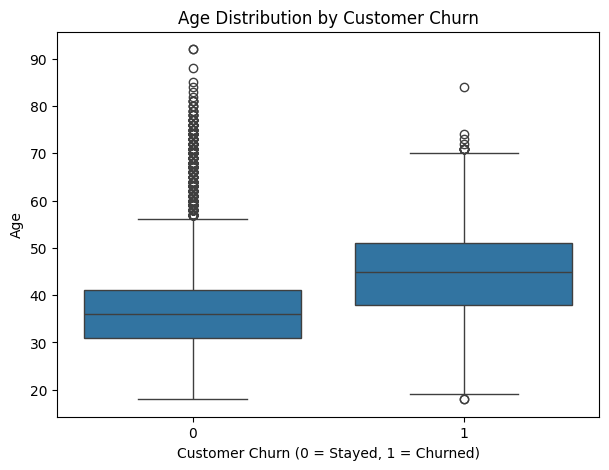

In [14]:
plt.figure(figsize=(7,5))

sns.boxplot(x="Exited", y="Age", data=df)

plt.title("Age Distribution by Customer Churn")
plt.xlabel("Customer Churn (0 = Stayed, 1 = Churned)")
plt.ylabel("Age")

plt.show()

In [13]:
df.groupby("Exited")["Age"].mean()

Exited
0    37.408389
1    44.837997
Name: Age, dtype: float64

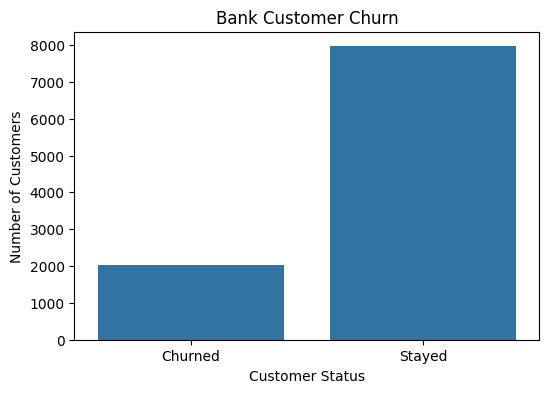

In [12]:
churn_labels = ["Stayed", "Churned"]

plt.figure(figsize=(6,4))

sns.countplot(x=df["Exited"].map({0: "Stayed", 1: "Churned"}))

plt.title("Bank Customer Churn")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.show()

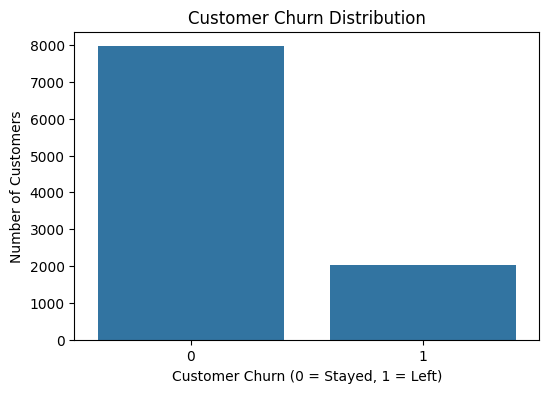

In [11]:
plt.figure(figsize=(6,4))

sns.countplot(x="Exited", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")

plt.show()


In [10]:
churn_percentage = df["Exited"].value_counts(normalize=True) * 100

print(churn_percentage)

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [9]:
churn_count = df["Exited"].value_counts()

print(churn_count)

Exited
0    7963
1    2037
Name: count, dtype: int64


In [8]:
df.describe()


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [4]:
print(df.columns.tolist())


['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10000
Columns: 14


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/Churn_Modelling.csv")

df.head()




,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
